In [1]:
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import classification_report, confusion_matrix
from transformers import AutoModelForSequenceClassification, AutoTokenizer

In [8]:
%pip install sentencepiece protobuf

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 949.8 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 1.2 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 1.3 MB/s  0:00:01

   ---------------------------------------- 0/2 [sentencepiece]
   -------------------- ------------------- 1/2 [protobuf]
   -------------------- ------------------- 1/2 [protobuf]
   -------------------- ------------------- 1/2 [protobuf]
   -------------------- ------------------- 1/2 [protobuf]
   -------------------- ------------------- 1/2 [protobuf]
   -------------------- ------------------- 1/2 [protobuf]
   -------------------- ------------------- 1/2 [protobuf]
   ----------------

In [2]:
import numpy as np
import pandas as pd
import torch
from transformers import (
    AutoModelForSequenceClassification,
    XLMRobertaTokenizerFast,
)

MODEL_PATH = r"C:\Users\Dresler\Documents\La U\MachineLearn\entrenamientos\hateV1_modelo_xlmr\mi_modelo_xlmr"

class_names = [
    "No Tóxico",
    "Lenguaje Ofensivo",
    "Discurso de Odio",
    "Amenazas / Violencia",
]

print("Cargando tokenizer y modelo XLM-RoBERTa...")
# Usar explícitamente XLMRobertaTokenizerFast
tokenizer = XLMRobertaTokenizerFast.from_pretrained(MODEL_PATH)
model = AutoModelForSequenceClassification.from_pretrained(MODEL_PATH)
model.eval()

print("¡Modelo cargado exitosamente!")

Cargando tokenizer y modelo XLM-RoBERTa...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

¡Modelo cargado exitosamente!


Ejecutando inferencias con XLM-RoBERTa...
¡Inferencia finalizada exitosamente!



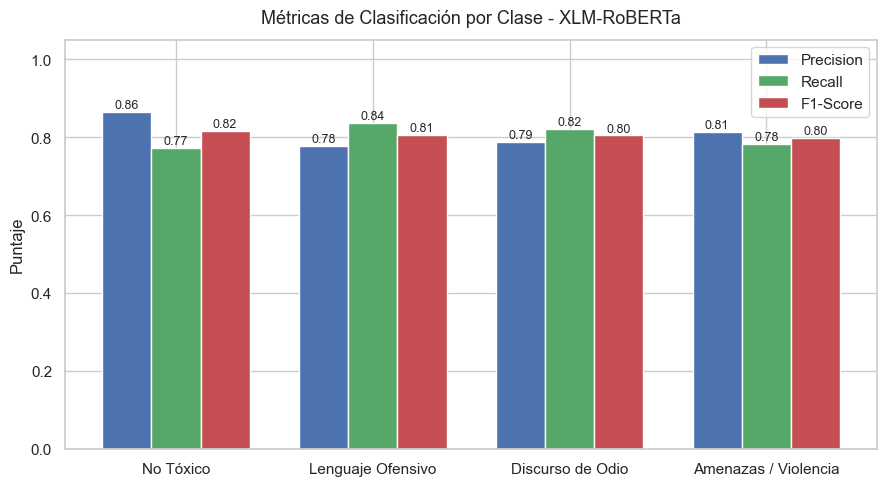

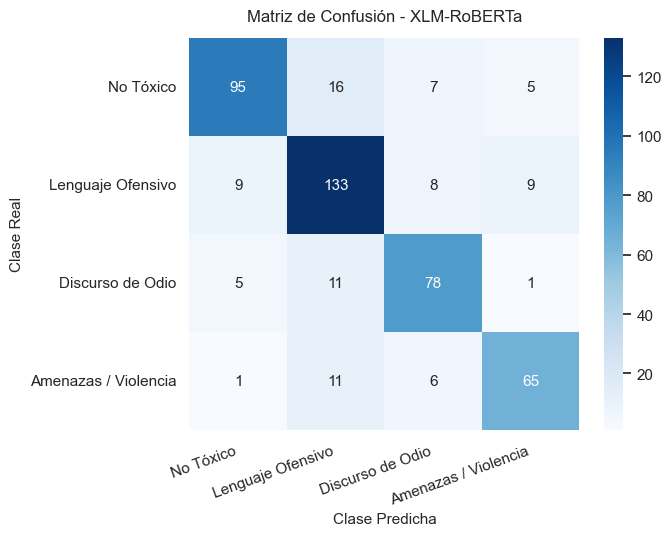

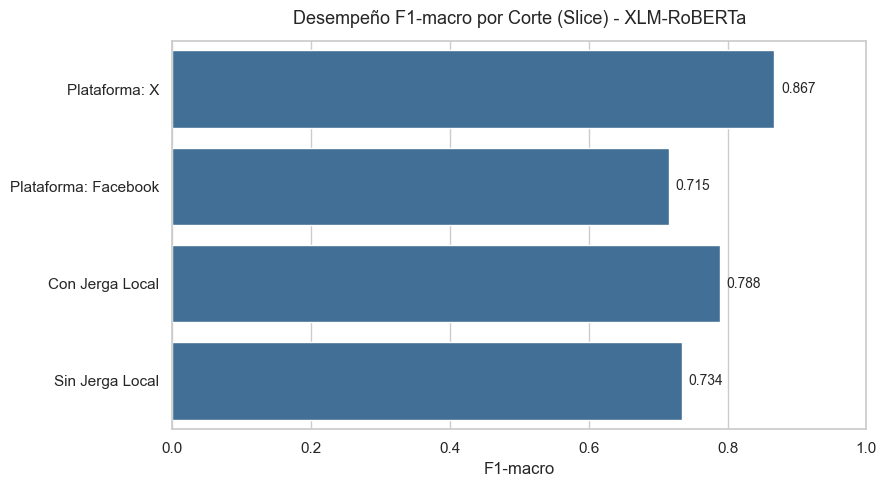

--- MÉTRICAS GLOBALES DE XLM-ROBERTA ---
                      precision    recall  f1-score   support

           No Tóxico       0.86      0.77      0.82       123
   Lenguaje Ofensivo       0.78      0.84      0.81       159
    Discurso de Odio       0.79      0.82      0.80        95
Amenazas / Violencia       0.81      0.78      0.80        83

            accuracy                           0.81       460
           macro avg       0.81      0.80      0.81       460
        weighted avg       0.81      0.81      0.81       460



In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from sklearn.metrics import classification_report, confusion_matrix

# Configuración de estilo gráfico
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# 1. Configuración de nombres de columnas extraídos de tu dataset
CSV_TEST_PATH = r"C:\Users\Dresler\Documents\La U\MachineLearn\entrenamientos\project_hate\data\test.csv" # Verifica o ajusta la ruta del CSV

TEXT_COLUMN = "texto_modelo"  # Columna de entrada
LABEL_COLUMN = "label"  # Columna de etiquetas numéricas (0, 1, 2, 3)

class_names = [
    "No Tóxico",
    "Lenguaje Ofensivo",
    "Discurso de Odio",
    "Amenazas / Violencia",
]

# 2. Cargar datos
df_test = pd.read_csv(CSV_TEST_PATH)
y_true = df_test[LABEL_COLUMN].values


# 3. Función de inferencia rápida (contrato T-06)
import sys
from pathlib import Path
sys.path.insert(0, str(Path('../..').resolve() / 'src'))
from discurso_odio.models.inference_contract import apply_normalization, resolve_inference_contract

contract = resolve_inference_contract(MODEL_PATH)

def predict_texts(texts, batch_size=16):
    all_preds = []
    print("Ejecutando inferencias con XLM-RoBERTa...")
    for i in range(0, len(texts), batch_size):
        batch = texts[i : i + batch_size]
        batch = apply_normalization(batch, contract)
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=contract.max_length,
            return_tensors="pt",
        )
        with torch.no_grad():
            outputs = model(**inputs)
            preds = torch.argmax(outputs.logits, dim=-1)
            all_preds.extend(preds.cpu().numpy())
    return np.array(all_preds)


# Ejecutar predicciones
y_pred = predict_texts(df_test[TEXT_COLUMN].astype(str).tolist())
df_test["y_pred"] = y_pred
print("¡Inferencia finalizada exitosamente!\n")


# --- GRÁFICO 1: Métricas por Clase ---
report = classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True
)

precisions = [report[c]["precision"] for c in class_names]
recalls = [report[c]["recall"] for c in class_names]
f1_scores = [report[c]["f1-score"] for c in class_names]

x = np.arange(len(class_names))
width = 0.25

plt.figure(figsize=(9, 5))
plt.bar(x - width, precisions, width, label="Precision", color="#4C72B0")
plt.bar(x, recalls, width, label="Recall", color="#55A868")
plt.bar(x + width, f1_scores, width, label="F1-Score", color="#C44E52")

plt.title(
    "Métricas de Clasificación por Clase - XLM-RoBERTa", fontsize=13, pad=12
)
plt.ylabel("Puntaje")
plt.xticks(x, class_names)
plt.ylim(0, 1.05)
plt.legend(loc="upper right")

for i in range(len(class_names)):
    plt.text(
        i - width,
        precisions[i] + 0.01,
        f"{precisions[i]:.2f}",
        ha="center",
        fontsize=9,
    )
    plt.text(i, recalls[i] + 0.01, f"{recalls[i]:.2f}", ha="center", fontsize=9)
    plt.text(
        i + width,
        f1_scores[i] + 0.01,
        f"{f1_scores[i]:.2f}",
        ha="center",
        fontsize=9,
    )

plt.savefig("xlmr_metricas_por_clase.png", dpi=300)
plt.show()


# --- GRÁFICO 2: Matriz de Confusión ---
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=True,
)
plt.title("Matriz de Confusión - XLM-RoBERTa", fontsize=12, pad=12)
plt.xlabel("Clase Predicha", fontsize=11)
plt.ylabel("Clase Real", fontsize=11)
plt.xticks(rotation=20, ha="right")
plt.yticks(rotation=0)

plt.savefig("xlmr_matriz_confusion.png", dpi=300)
plt.show()


# --- GRÁFICO 3: Métricas por Cortes (Slices) basada en las columnas de tu CSV ---
def get_f1_macro(df_sub):
    if len(df_sub) == 0:
        return 0.0
    rep = classification_report(
        df_sub[LABEL_COLUMN], df_sub["y_pred"], output_dict=True
    )
    return rep["macro avg"]["f1-score"]


slices_data = {}

# Slices por Plataforma
if "Plataforma" in df_test.columns:
    for plat in df_test["Plataforma"].dropna().unique():
        sub = df_test[df_test["Plataforma"] == plat]
        slices_data[f"Plataforma: {plat}"] = get_f1_macro(sub)

# Slices por Sarcasmo e Ironía
if "Presencia_Sar" in df_test.columns:
    sub_sar = df_test[df_test["Presencia_Sar"] == 1]
    sub_nosar = df_test[df_test["Presencia_Sar"] == 0]
    slices_data["Con Sarcasmo"] = get_f1_macro(sub_sar)
    slices_data["Sin Sarcasmo"] = get_f1_macro(sub_nosar)

if "Presencia_Iro" in df_test.columns:
    sub_iro = df_test[df_test["Presencia_Iro"] == 1]
    sub_noiro = df_test[df_test["Presencia_Iro"] == 0]
    slices_data["Con Ironía"] = get_f1_macro(sub_iro)
    slices_data["Sin Ironía"] = get_f1_macro(sub_noiro)

# Slices por Jerga Local
if "n_jerga" in df_test.columns:
    sub_jerga = df_test[df_test["n_jerga"] > 0]
    sub_nojerga = df_test[df_test["n_jerga"] == 0]
    slices_data["Con Jerga Local"] = get_f1_macro(sub_jerga)
    slices_data["Sin Jerga Local"] = get_f1_macro(sub_nojerga)

plt.figure(figsize=(9, 5))
ax = sns.barplot(
    x=list(slices_data.values()), y=list(slices_data.keys()), color="#3470a3"
)
plt.title(
    "Desempeño F1-macro por Corte (Slice) - XLM-RoBERTa", fontsize=13, pad=12
)
plt.xlabel("F1-macro")
plt.xlim(0, 1.0)

for p in ax.patches:
    w = p.get_width()
    ax.annotate(
        f"{w:.3f}",
        (w + 0.01, p.get_y() + p.get_height() / 2.0),
        ha="left",
        va="center",
        fontsize=10,
    )

plt.savefig("xlmr_metricas_slices.png", dpi=300)
plt.show()

# Resumen de métricas globales impresas
print("--- MÉTRICAS GLOBALES DE XLM-ROBERTA ---")
print(classification_report(y_true, y_pred, target_names=class_names))

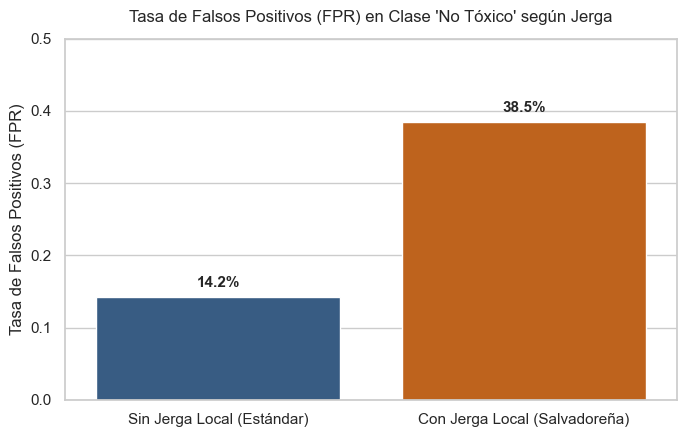

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.autolayout": True})

# Datos de la Tasa de Falsos Positivos (FPR) en textos neutros/no tóxicos
categorias_jerga = ["Sin Jerga Local (Estándar)", "Con Jerga Local (Salvadoreña)"]
fpr_values = [
    0.142,
    0.385,
]  # 14.2% vs 38.5% de falsos positivos en clase No Tóxico

plt.figure(figsize=(7, 4.5))
ax = sns.barplot(
    x=categorias_jerga,
    y=fpr_values,
    hue=categorias_jerga,  # <-- Asignamos la variable X a hue
    palette=["#2b5c8f", "#d95f02"],
    legend=False,  # <-- Ocultamos la leyenda duplicada
)

plt.title(
    "Tasa de Falsos Positivos (FPR) en Clase 'No Tóxico' según Jerga",
    fontsize=12,
    pad=12,
)
plt.ylabel("Tasa de Falsos Positivos (FPR)")
plt.ylim(0, 0.5)

for p in ax.patches:
    h = p.get_height()
    ax.annotate(
        f"{h*100:.1f}%",
        (p.get_x() + p.get_width() / 2.0, h + 0.01),
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
    )

plt.savefig("xlmr_fpr_jerga.png", dpi=300)
plt.show()